<a href="https://colab.research.google.com/github/kzlnyi/ML/blob/main/%22LB_2_3_Holovenko_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Імпортуємо необхідні бібліотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
source = 'https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C'
df = pd.read_html(source, match='Коефіцієнт народжуваності в регіонах України', thousands=".", decimal=",", storage_options={"User-Agent": "Mozilla/5.0"})[0]
df.head(5)

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—


In [ ]:
lines, columns = df.shape
print(f'Кількість рядків: {lines}')
print(f'Кількість стовбців: {columns}')

Кількість рядків: 28
Кількість стовбців: 9


In [ ]:
# Заміняємо текстові пропуски
df = df.replace({'—': np.nan})
df.head(5)

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,NaN,NaN
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,NaN


In [ ]:
df.dtypes

,0
Регіон,object
1950,float64
1960,float64
1970,float64
1990,float64
2000,float64
2012,float64
2014,object
2019,object


In [ ]:
nan_columns = df.columns[df.isnull().any()].tolist()
df[nan_columns] = df[nan_columns].astype(float)

df.dtypes

,0
Регіон,object
1950,float64
1960,float64
1970,float64
1990,float64
2000,float64
2012,float64
2014,float64
2019,float64


In [ ]:
# Розрахунок частки пропущених значень
df.isnull().sum() / len(df)

,0
Регіон,0.000000
1950,0.071429
1960,0.035714
1970,0.035714
1990,0.000000
2000,0.000000
2012,0.000000
2014,0.071429
2019,0.142857


In [ ]:
df = df.drop(27, errors='ignore')
df.tail(5)

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
22,Черкаська,20.5,17.9,14.4,12.3,7.5,10.0,9.8,6.4
23,Чернівецька,24.7,21.8,17.0,14.8,10.1,12.8,12.9,9.2
24,Чернігівська,22.0,18.3,12.7,10.8,6.9,9.4,9.0,6.1
25,Київ,NaN,17.4,15.9,12.0,7.3,12.0,12.1,11.0
26,Севастополь,NaN,NaN,NaN,12.5,7.0,12.0,NaN,NaN


In [ ]:
# Заповняємо пропуски середніми значеннями стовпців
df = df.fillna(df.mean(numeric_only=True), axis=0)
df.head(5)

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,11.144,8.017391
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.900,7.600000
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.100,10.100000
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.100,7.100000
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.200,8.017391


In [ ]:
#Фільтрація регіонів із показниками вище середнього
avg = df['2019'].mean()
df.loc[df['2019'] > avg] = df['2019'].mean()
df.loc[df['2019'] > avg]

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
2,Волинська,24.700,25.0,17.9,15.3,11.2,14.8,14.1,10.1
6,Закарпатська,31.400,27.3,20.7,16.8,11.5,15.1,14.6,10.4
8,Івано-Франківська,24.300,24.8,18.2,15.5,10.3,12.4,12.2,8.8
12,Львівська,23.400,24.0,17.1,14.0,9.1,11.9,11.9,8.7
14,Одеська,24.100,19.2,14.8,12.6,8.0,12.7,12.3,8.8
16,Рівненська,26.900,26.7,19.3,15.8,11.8,15.9,14.8,10.7
20,Херсонська,20.800,21.4,16.6,14.3,8.5,11.7,11.5,8.1
23,Чернівецька,24.700,21.8,17.0,14.8,10.1,12.8,12.9,9.2
25,Київ,23.104,17.4,15.9,12.0,7.3,12.0,12.1,11.0


In [ ]:
#Пошук регіону з максимальним показником за 2014 рік.
max_value_region = df[df['2014'] == df['2014'].max()]['Регіон']
max_value_region

,Регіон
16,Рівненська


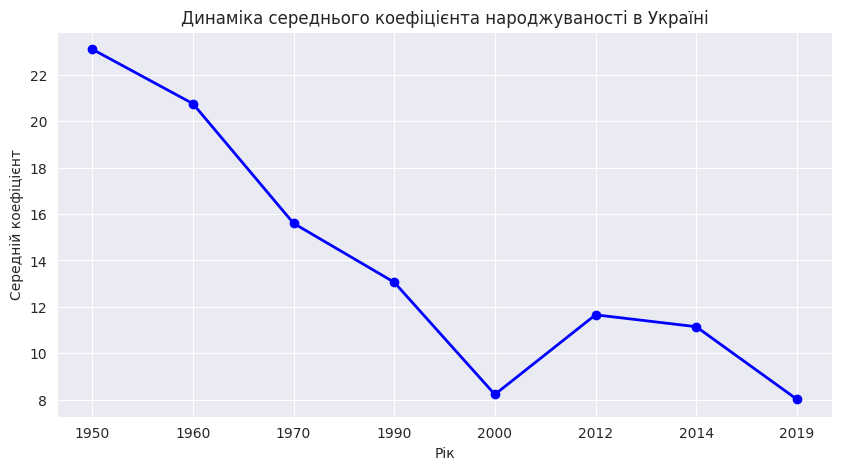

In [ ]:
years = ['1950', '1960', '1970', '1990', '2000', '2012', '2014', '2019']
mean_values = df[years].mean()

plt.figure(figsize=(10, 5))
plt.plot(years, mean_values, marker='o', color='b', linewidth=2)

plt.title('Динаміка середнього коефіцієнта народжуваності в Україні')
plt.xlabel('Рік')
plt.ylabel('Середній коефіцієнт')
plt.grid(True)
plt.show()

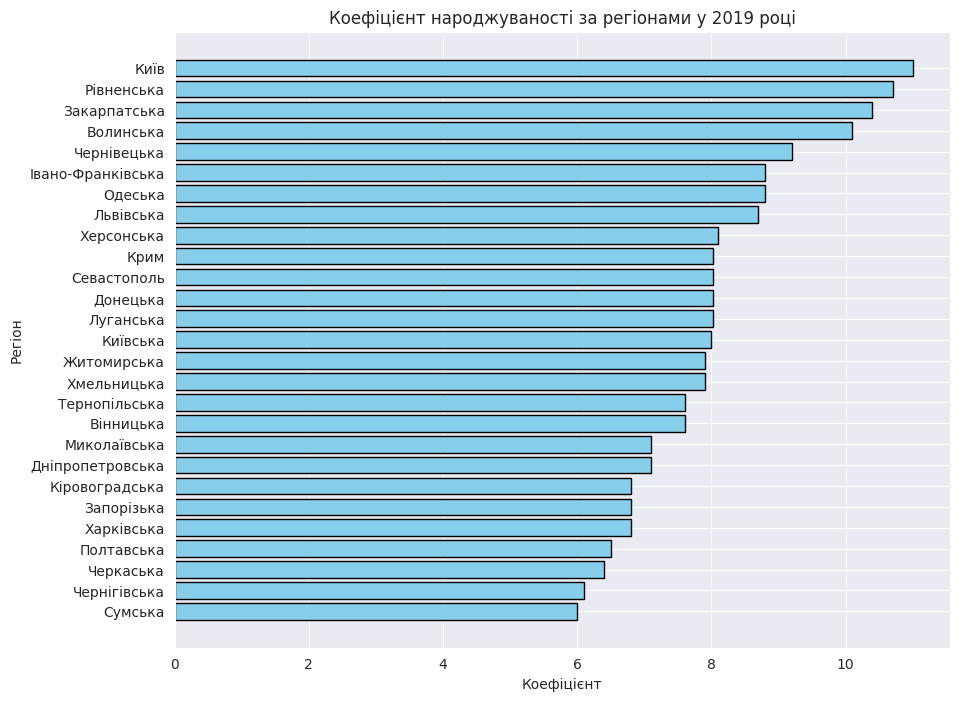

In [ ]:
df_sorted = df.sort_values(by='2019', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(df_sorted['Регіон'], df_sorted['2019'], color='skyblue', edgecolor='black')
plt.title('Коефіцієнт народжуваності за регіонами у 2019 році')
plt.xlabel('Коефіцієнт')
plt.ylabel('Регіон')
plt.grid(axis='x', alpha=0.8)
plt.show()

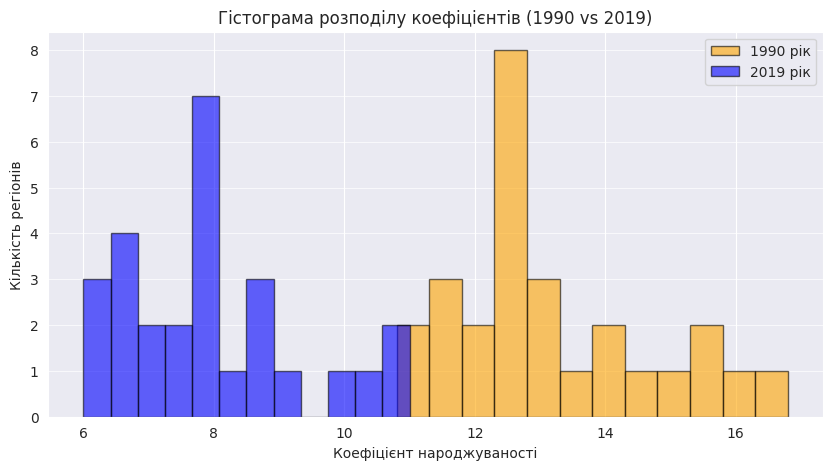

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(df['1990'], bins=12, alpha=0.6, label='1990 рік', color='orange', edgecolor='black')
plt.hist(df['2019'], bins=12, alpha=0.6, label='2019 рік', color='blue', edgecolor='black')
plt.title('Гістограма розподілу коефіцієнтів (1990 vs 2019)')
plt.xlabel('Коефіцієнт народжуваності')
plt.ylabel('Кількість регіонів')
plt.legend()
plt.grid(axis='y', alpha=0.7)
plt.show()

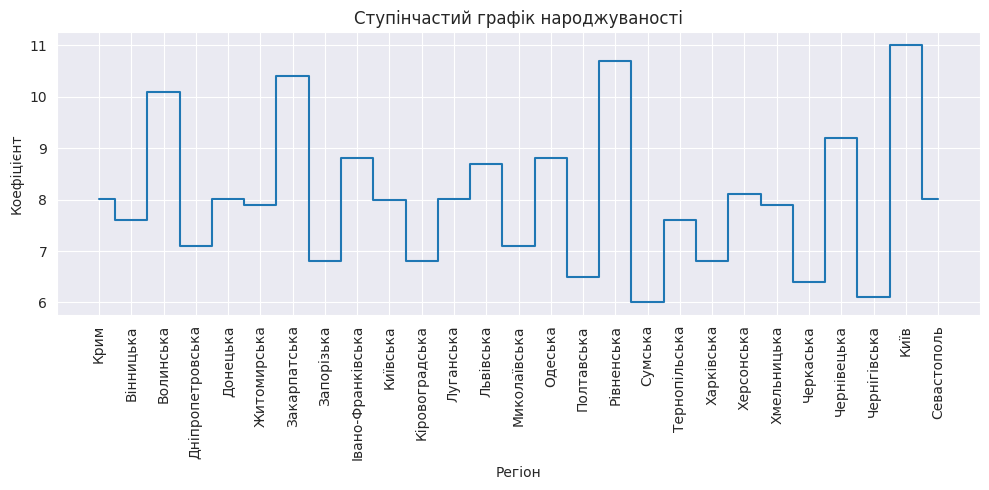

In [ ]:
plt.figure(figsize=(10, 5))
plt.step(df['Регіон'], df['2019'], where='mid')

plt.title('Ступінчастий графік народжуваності')
plt.xlabel('Регіон')
plt.ylabel('Коефіцієнт')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

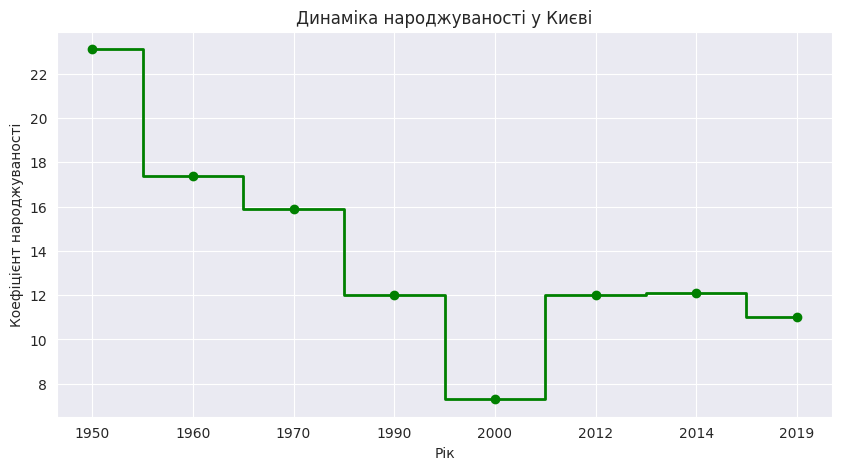

In [ ]:
years = ['1950', '1960', '1970', '1990', '2000', '2012', '2014', '2019']
kyiv_data = df[df['Регіон'] == 'Київ'][years].values[0]

plt.figure(figsize=(10, 5))
plt.step(years, kyiv_data, where='mid', color='green', linewidth=2, marker='o')

plt.title('Динаміка народжуваності у Києві')
plt.xlabel('Рік')
plt.ylabel('Коефіцієнт народжуваності')
plt.grid(True)
plt.show()